# Resolved Turbulent Kinetic Energy (TKE) — Simulation

Computes the **resolved** TKE from the time-averaged Reynolds-stress tensor stored in the
transformed layer CSVs.

The diagonal of the Reynolds-stress tensor gives the normal stresses:

| column        | component |
|---------------|-----------|
| `Re_tensor_0` | $\overline{u'u'}$ |
| `Re_tensor_1` | $\overline{v'v'}$ |
| `Re_tensor_2` | $\overline{w'w'}$ |

$$k_{res} = \tfrac{1}{2}\left(\overline{u'u'} + \overline{v'v'} + \overline{w'w'}\right)
         = \tfrac{1}{2}\left(\texttt{Re\_tensor\_0} + \texttt{Re\_tensor\_1} + \texttt{Re\_tensor\_2}\right)$$

Coordinate convention (30° sets): `Points_0` = X (transverse), `Points_1` = Z (streamwise / height).
Each `Lxx` file is a distinct 10 mm slab (L03: 0.02–0.03 m … L17: 0.16–0.17 m).

In [7]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- CONFIG -----------------------------------------------------------------
PROJECT_ROOT = Path('/mnt/d/0_Work/A4-A1_2')
DATA_DIR = PROJECT_ROOT / '30' / 'sim' / '30_Re_100' / 'Pos3_transformed_all'
POS, RE = 'Pos3', 'Re100'   # only used for titles / output names

OUT_DIR = PROJECT_ROOT / 'mypaper' / 'images' / '30_Re_100' / 'TKE'
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

In [8]:
def load_layer(path):
    """Read one transformed layer CSV and add resolved-TKE + geometry helpers."""
    df = pd.read_csv(path)
    m = re.search(r'_L(\d+)_', path.name)
    df['layer'] = int(m.group(1)) if m else -1

    # normal stresses (uu, vv, ww) -> resolved TKE
    df['uu'] = df['Re_tensor_0']
    df['vv'] = df['Re_tensor_1']
    df['ww'] = df['Re_tensor_2']
    df['TKE'] = 0.5 * (df['uu'] + df['vv'] + df['ww'])

    # geometry: X transverse, Z streamwise (layer-local Z overlays the slabs)
    df['X'] = df['Points_0']
    df['Z'] = df['Points_1']
    df['Z_local'] = df['Points_1'] - df['Points_1'].min()
    return df


def load_all(data_dir):
    files = sorted(Path(data_dir).glob('*_T_transformed.csv'))
    if not files:
        raise FileNotFoundError(f'No *_T_transformed.csv found in {data_dir}')
    df = pd.concat((load_layer(f) for f in files), ignore_index=True)
    print(f'Loaded {len(files)} layers, {len(df):,} points from {data_dir.name}')
    return df

In [9]:
df = load_all(DATA_DIR)
df[['layer', 'X', 'Z', 'uu', 'vv', 'ww', 'TKE']].describe()

Loaded 15 layers, 126,058 points from Pos3_transformed_all


,layer,X,Z,uu,vv,ww,TKE
count,126058.000000,1.260580e+05,126058.000000,1.260580e+05,1.260580e+05,1.260580e+05,1.260580e+05
mean,10.088102,-3.021509e-06,0.095881,1.234416e-02,1.430289e-02,9.823779e-02,6.244241e-02
std,4.316231,1.730578e-02,0.043258,2.092891e-02,2.366228e-02,1.484241e-01,7.333561e-02
min,3.000000,-2.985013e-02,0.020000,2.078898e-10,7.900263e-11,7.423236e-13,7.167397e-09
25%,6.000000,-1.489617e-02,0.059350,5.075291e-04,5.611387e-04,1.377471e-04,7.622777e-03
50%,10.000000,6.495988e-08,0.096250,3.209916e-03,3.678031e-03,5.687380e-03,3.102134e-02
75%,14.000000,1.489617e-02,0.133150,1.485624e-02,1.770065e-02,1.693639e-01,9.206701e-02
max,17.000000,2.985013e-02,0.170000,2.401732e-01,2.460823e-01,6.478616e-01,3.757705e-01


## TKE vs height (streamwise Z)

Mean and spread of the resolved TKE, one point per layer at its true Z height.

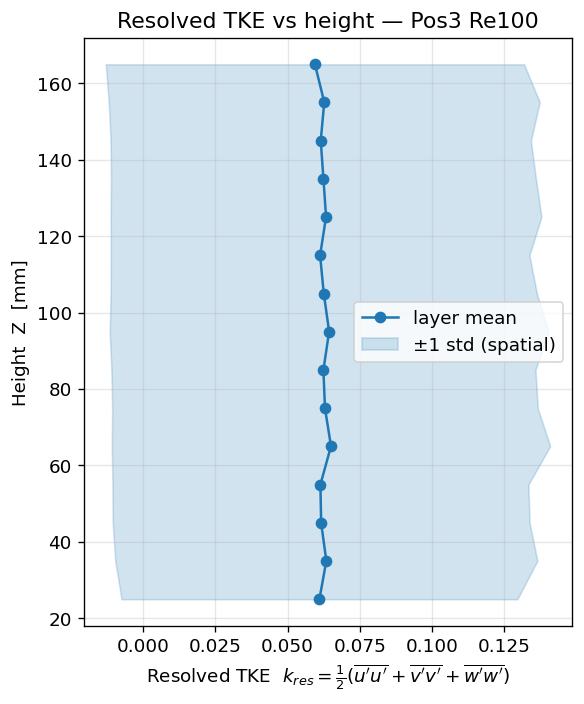

In [10]:
prof = (df.groupby('layer')
          .agg(Z=('Z', 'mean'), TKE_mean=('TKE', 'mean'), TKE_std=('TKE', 'std'))
          .reset_index())

fig, ax = plt.subplots(figsize=(5, 6))
ax.plot(prof['TKE_mean'], prof['Z'] * 1e3, 'o-', color='#1f77b4', label='layer mean')
ax.fill_betweenx(prof['Z'] * 1e3,
                 prof['TKE_mean'] - prof['TKE_std'],
                 prof['TKE_mean'] + prof['TKE_std'],
                 alpha=0.2, color='#1f77b4', label='±1 std (spatial)')
ax.set_xlabel(r"Resolved TKE  $k_{res}=\frac{1}{2}(\overline{u'u'}+\overline{v'v'}+\overline{w'w'})$")
ax.set_ylabel('Height  Z  [mm]')
ax.set_title(f'Resolved TKE vs height — {POS} {RE}')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / f'TKE_vs_height_{POS}_{RE}.png', bbox_inches='tight')
plt.show()

## Spatial TKE maps per layer

Each panel is one slab in its (X, Z) plane, colored by resolved TKE (shared color scale).

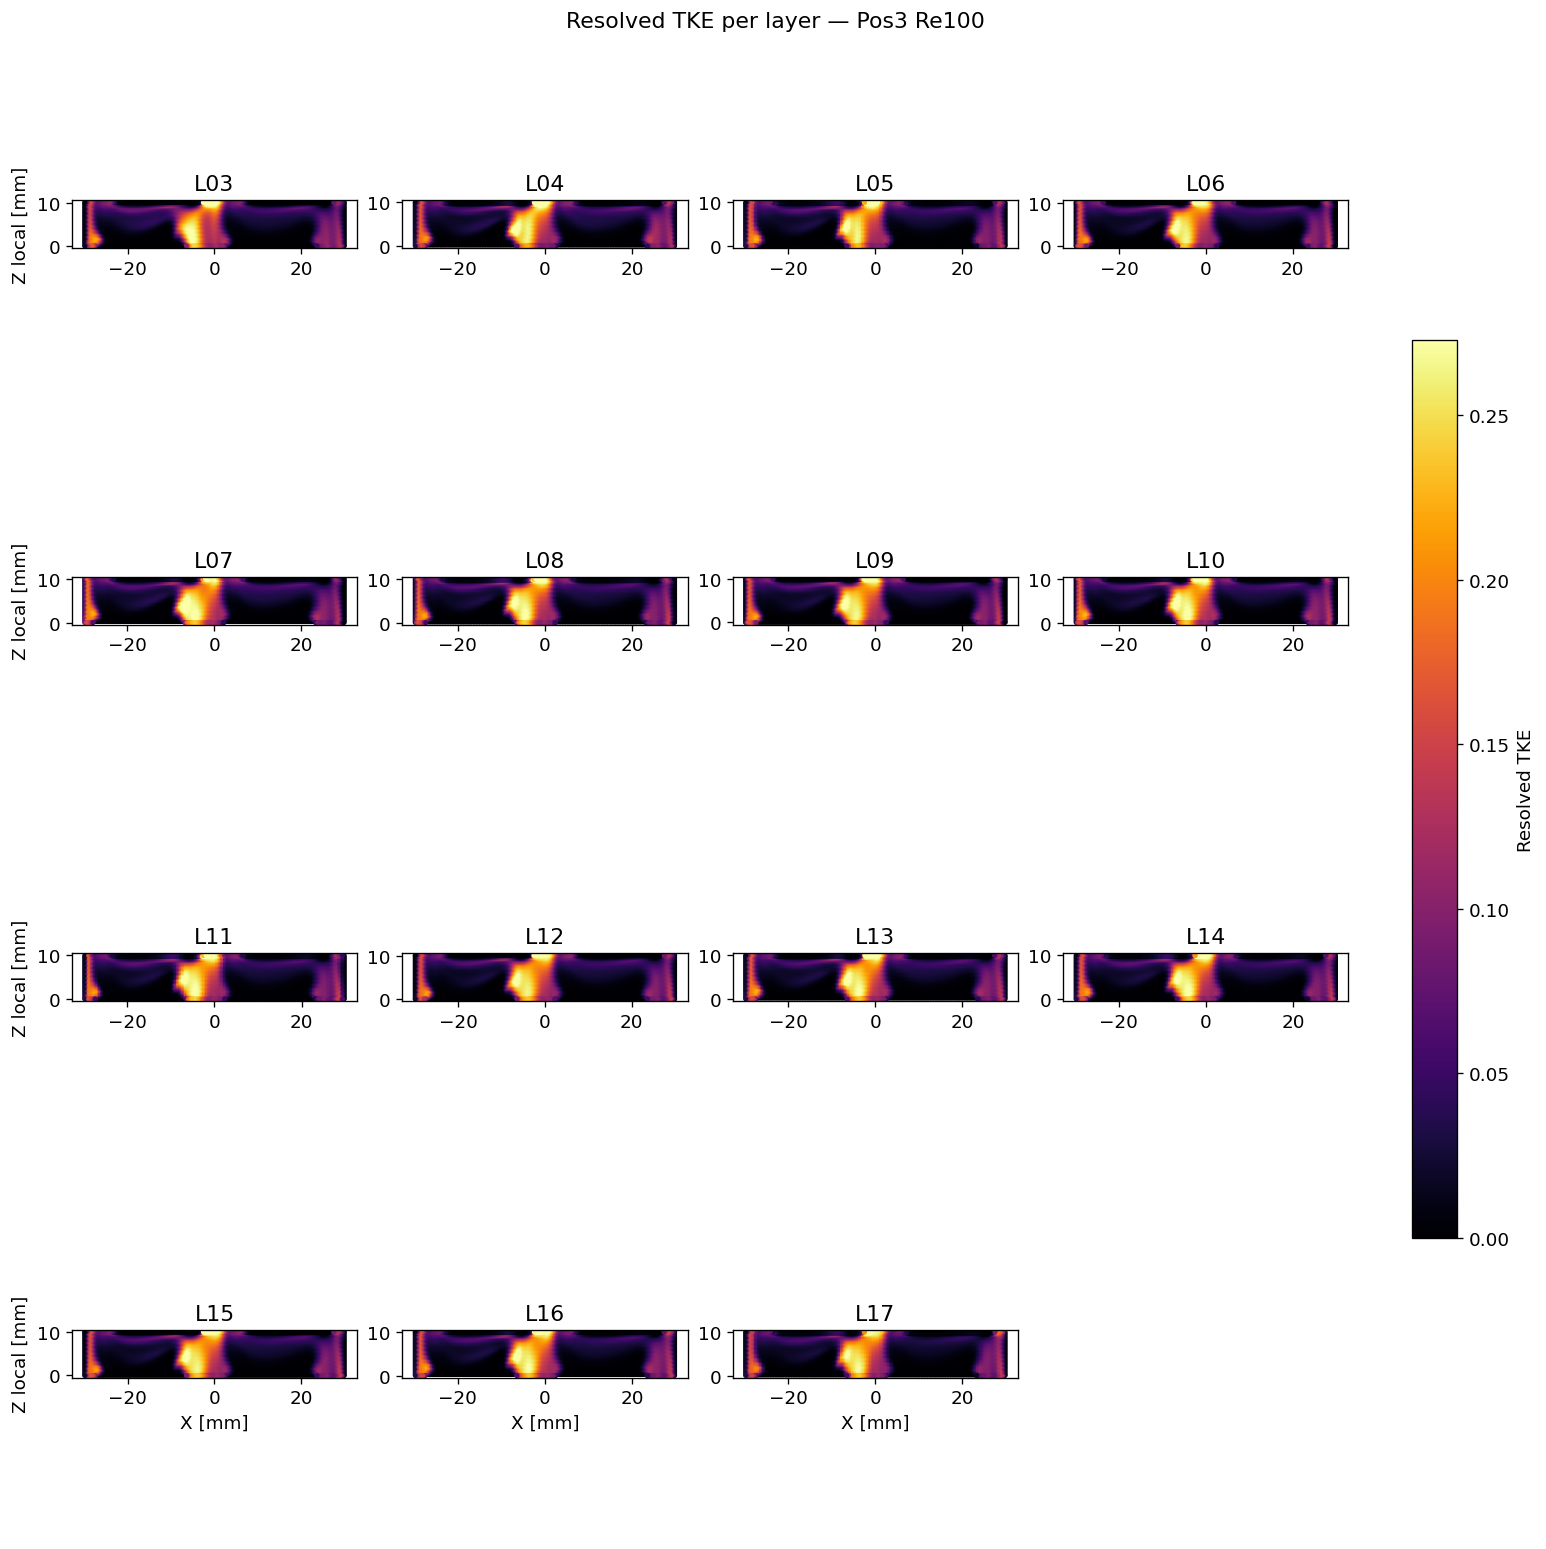

In [11]:
layers = sorted(df['layer'].unique())
ncol = 4
nrow = int(np.ceil(len(layers) / ncol))
vmax = np.nanpercentile(df['TKE'], 99)  # clip extremes for readable color range

fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.2 * nrow),
                         squeeze=False, constrained_layout=True)
sc = None
for ax, L in zip(axes.ravel(), layers):
    d = df[df['layer'] == L]
    sc = ax.scatter(d['X'] * 1e3, d['Z_local'] * 1e3, c=d['TKE'],
                    s=4, cmap='inferno', vmin=0, vmax=vmax)
    ax.set_title(f'L{L:02d}')
    ax.set_aspect('equal')
for ax in axes.ravel()[len(layers):]:
    ax.axis('off')
for ax in axes[-1]:
    ax.set_xlabel('X [mm]')
for ax in axes[:, 0]:
    ax.set_ylabel('Z local [mm]')
fig.colorbar(sc, ax=axes, shrink=0.6, label='Resolved TKE')
fig.suptitle(f'Resolved TKE per layer — {POS} {RE}')
fig.savefig(OUT_DIR / f'TKE_maps_per_layer_{POS}_{RE}.png', bbox_inches='tight')
plt.show()

## Normal-stress contributions

How uu, vv, ww each contribute to the TKE with height — indicates anisotropy.

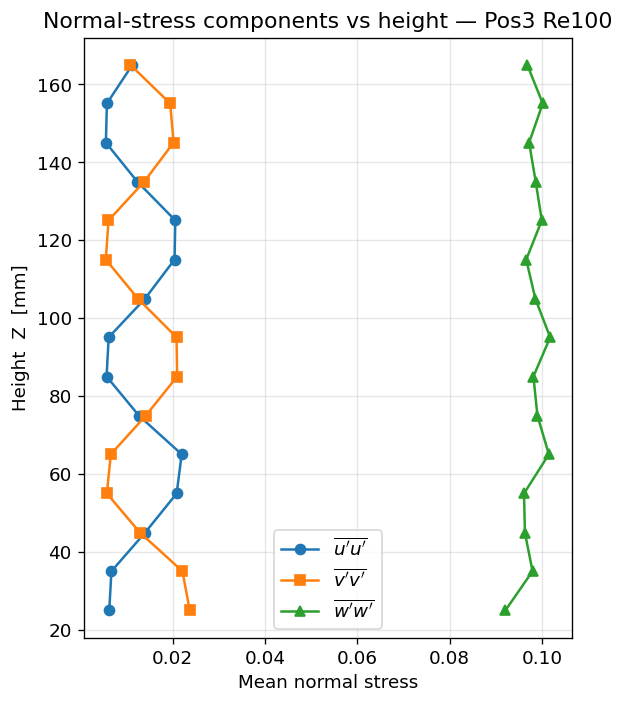

In [12]:
comp = df.groupby('layer').agg(Z=('Z', 'mean'), uu=('uu', 'mean'),
                               vv=('vv', 'mean'), ww=('ww', 'mean')).reset_index()

fig, ax = plt.subplots(figsize=(5, 6))
ax.plot(comp['uu'], comp['Z'] * 1e3, 'o-', label=r"$\overline{u'u'}$")
ax.plot(comp['vv'], comp['Z'] * 1e3, 's-', label=r"$\overline{v'v'}$")
ax.plot(comp['ww'], comp['Z'] * 1e3, '^-', label=r"$\overline{w'w'}$")
ax.set_xlabel('Mean normal stress')
ax.set_ylabel('Height  Z  [mm]')
ax.set_title(f'Normal-stress components vs height — {POS} {RE}')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / f'TKE_components_vs_height_{POS}_{RE}.png', bbox_inches='tight')
plt.show()

# Experiment vs Simulation TKE

The PIV files carry a `Turbulent_kinetic_energy` column equal to
$\tfrac12(\sigma_{Vx}^2+\sigma_{Vy}^2+\sigma_{Vz}^2)$ — a full 3-component TKE, directly
comparable to the resolved sim TKE. Experiment covers **L13–L17 only**, so the comparison
is restricted to those layers. Convention: **left = experiment (PIV), right = simulation**.

In [13]:
# ---- experiment (PIV) loader -------------------------------------------------
EXP_DIR = PROJECT_ROOT / '30' / 'exp' / '30_Re_100' / 'Pos3_transformed'


def load_exp_layer(path):
    """Read one PIV layer CSV and expose TKE + geometry with the same names as sim."""
    df = pd.read_csv(path)
    m = re.search(r'L(\d+)_', path.name)
    df['layer'] = int(m.group(1)) if m else -1

    # PIV already stores a 3-component TKE = 0.5*(sd_Vx^2 + sd_Vy^2 + sd_Vz^2)
    df['TKE'] = df['Turbulent_kinetic_energy']
    df['X'] = df['x']          # transverse
    df['Z'] = df['z']          # streamwise / height
    df['Z_local'] = df['z'] - df['z'].min()
    return df


def load_exp(data_dir):
    files = sorted(Path(data_dir).glob('*_T_transformed.csv'))
    if not files:
        raise FileNotFoundError(f'No *_T_transformed.csv found in {data_dir}')
    df = pd.concat((load_exp_layer(f) for f in files), ignore_index=True)
    # PIV masks invalid vectors -> drop them so they don't bias means
    if 'isValid' in df.columns:
        df = df[df['isValid'] == 1].copy()
    print(f'Loaded {len(files)} EXP layers, {len(df):,} valid points from {data_dir.name}')
    return df


df_exp = load_exp(EXP_DIR)
common_layers = sorted(set(df['layer']).intersection(df_exp['layer']))
print('Overlapping layers (exp & sim):', common_layers)

Loaded 5 EXP layers, 33,304 valid points from Pos3_transformed
Overlapping layers (exp & sim): [13, 14, 15, 16, 17]


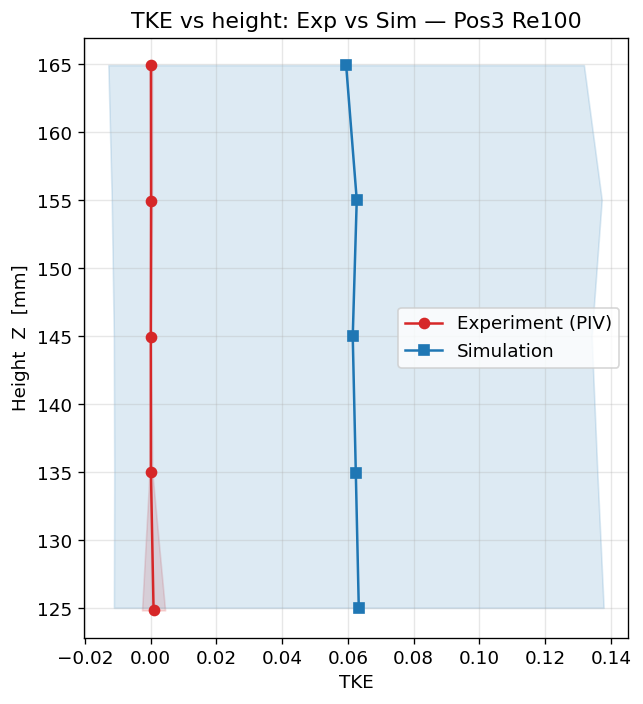

,layer,TKE_mean_exp,TKE_mean_sim,rel_diff_%
0,13,0.00090,0.06333,6923.09712
1,14,0.00009,0.06243,66032.93368
2,15,0.00006,0.06149,111675.81510
3,16,0.00015,0.06271,42599.75516
4,17,0.00011,0.05948,55513.81498


In [14]:
# ---- TKE vs height: exp vs sim (overlapping layers) --------------------------
def layer_profile(data, layers):
    p = (data[data['layer'].isin(layers)]
         .groupby('layer')
         .agg(Z=('Z', 'mean'), TKE_mean=('TKE', 'mean'), TKE_std=('TKE', 'std'))
         .reset_index())
    return p

p_exp = layer_profile(df_exp, common_layers)
p_sim = layer_profile(df, common_layers)

fig, ax = plt.subplots(figsize=(5.5, 6))
ax.plot(p_exp['TKE_mean'], p_exp['Z'] * 1e3, 'o-', color='#d62728', label='Experiment (PIV)')
ax.fill_betweenx(p_exp['Z'] * 1e3, p_exp['TKE_mean'] - p_exp['TKE_std'],
                 p_exp['TKE_mean'] + p_exp['TKE_std'], alpha=0.15, color='#d62728')
ax.plot(p_sim['TKE_mean'], p_sim['Z'] * 1e3, 's-', color='#1f77b4', label='Simulation')
ax.fill_betweenx(p_sim['Z'] * 1e3, p_sim['TKE_mean'] - p_sim['TKE_std'],
                 p_sim['TKE_mean'] + p_sim['TKE_std'], alpha=0.15, color='#1f77b4')
ax.set_xlabel('TKE')
ax.set_ylabel('Height  Z  [mm]')
ax.set_title(f'TKE vs height: Exp vs Sim — {POS} {RE}')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / f'TKE_vs_height_ExpVsSim_{POS}_{RE}.png', bbox_inches='tight')
plt.show()

# quantitative summary per layer
summary = p_exp.merge(p_sim, on='layer', suffixes=('_exp', '_sim'))
summary['rel_diff_%'] = 100 * (summary['TKE_mean_sim'] - summary['TKE_mean_exp']) / summary['TKE_mean_exp']
summary[['layer', 'TKE_mean_exp', 'TKE_mean_sim', 'rel_diff_%']].round(5)

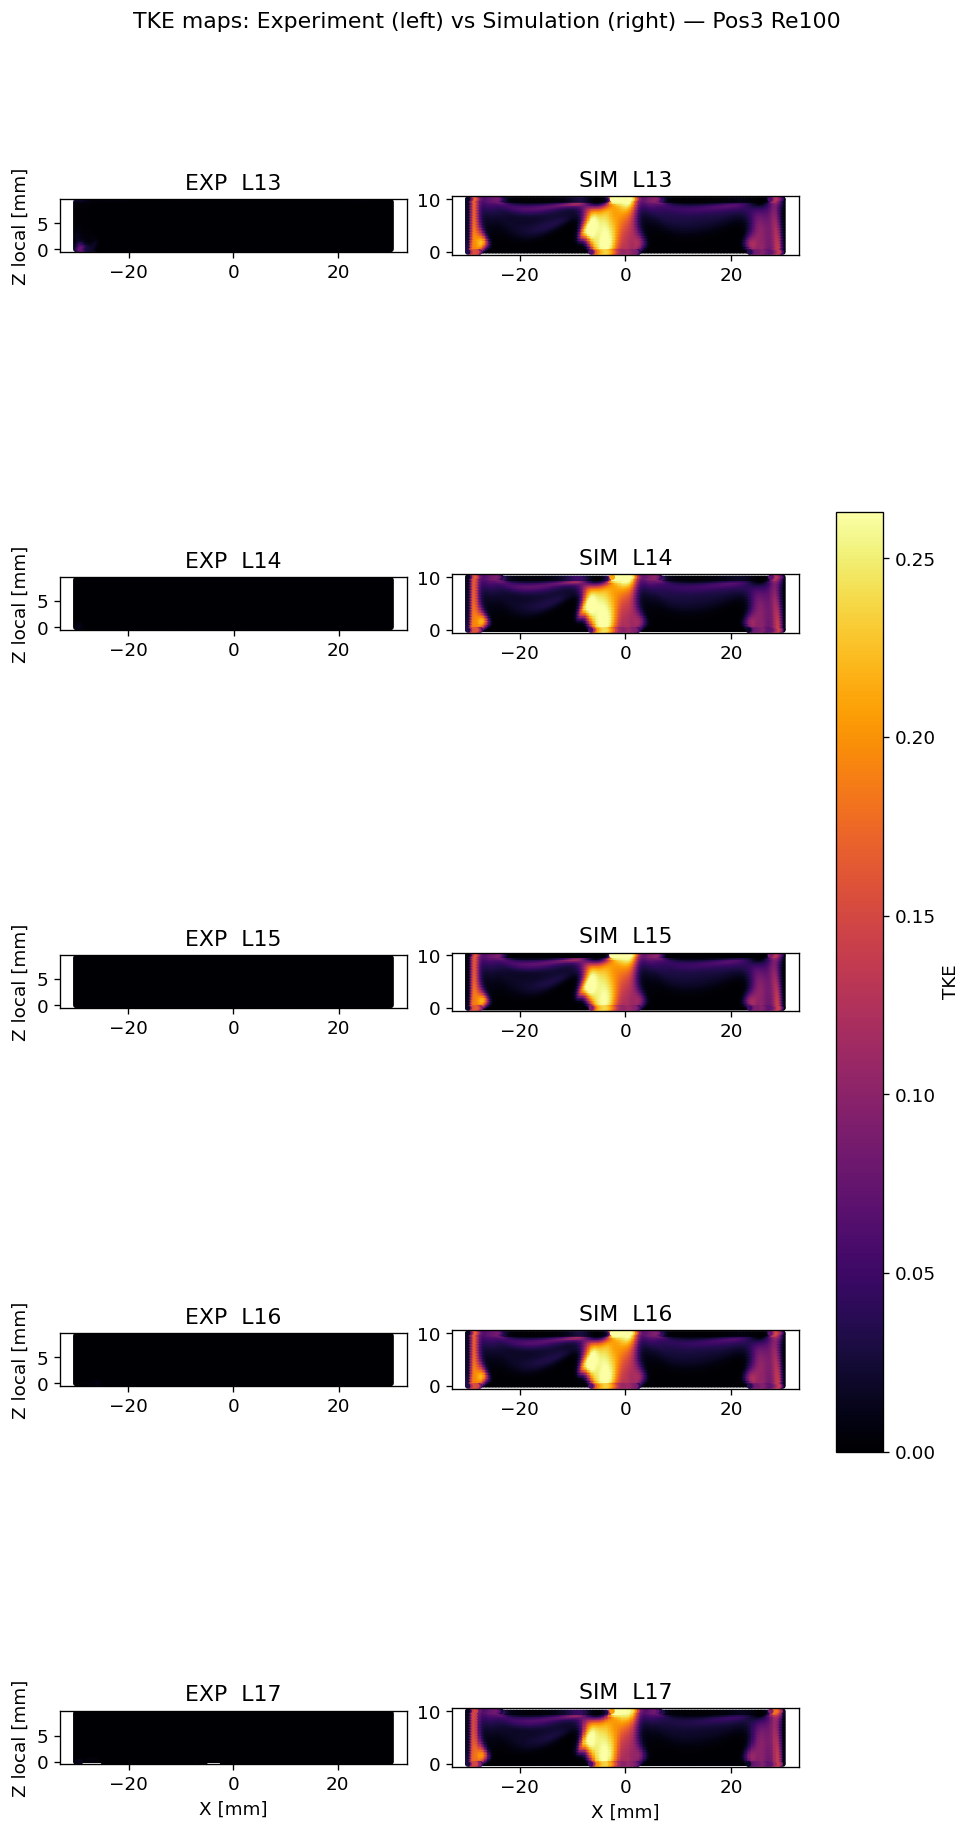

In [15]:
# ---- side-by-side spatial TKE maps: left = EXP, right = SIM ------------------
# one row per overlapping layer; shared color scale for a fair visual comparison
sub_exp = df_exp[df_exp['layer'].isin(common_layers)]
sub_sim = df[df['layer'].isin(common_layers)]
vmax = np.nanpercentile(pd.concat([sub_exp['TKE'], sub_sim['TKE']]), 99)

nrow = len(common_layers)
fig, axes = plt.subplots(nrow, 2, figsize=(8, 3.2 * nrow),
                         squeeze=False, constrained_layout=True)
sc = None
for i, L in enumerate(common_layers):
    for j, (data, tag) in enumerate([(sub_exp, 'EXP'), (sub_sim, 'SIM')]):
        d = data[data['layer'] == L]
        ax = axes[i, j]
        sc = ax.scatter(d['X'] * 1e3, d['Z_local'] * 1e3, c=d['TKE'],
                        s=5, cmap='inferno', vmin=0, vmax=vmax)
        ax.set_aspect('equal')
        ax.set_title(f'{tag}  L{L:02d}')
        if j == 0:
            ax.set_ylabel('Z local [mm]')
        if i == nrow - 1:
            ax.set_xlabel('X [mm]')

fig.colorbar(sc, ax=axes, shrink=0.5, label='TKE')
fig.suptitle(f'TKE maps: Experiment (left) vs Simulation (right) — {POS} {RE}')
fig.savefig(OUT_DIR / f'TKE_maps_ExpVsSim_{POS}_{RE}.png', bbox_inches='tight')
plt.show()